--- 1. Dataset Info & Missing Values ---
Shape: (891, 12)

Data Types & Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None

Missing Values per Column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp   

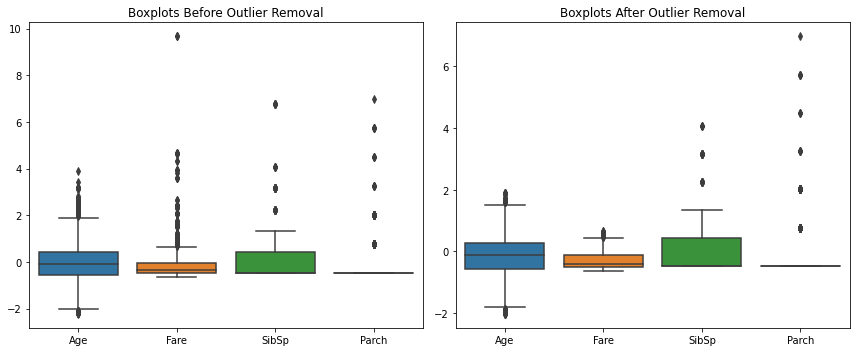


--- 5. Outlier Removal Summary ---
Rows before outlier removal: 891
Rows after outlier removal:  721
Final Cleaned DataFrame Shape: (721, 17)


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# ---------------------------------------------------------
# 1. Import the dataset and explore basic info (nulls, data types)
# ---------------------------------------------------------
df = pd.read_csv('Titanic-Dataset.csv')

print("--- 1. Dataset Info & Missing Values ---")
print("Shape:", df.shape)
print("\nData Types & Non-Null Counts:")
print(df.info())
print("\nMissing Values per Column:")
print(df.isnull().sum())
print("\nSummary Statistics:")
print(df.describe())

# ---------------------------------------------------------
# 2. Handle missing values using mean/median/imputation
# ---------------------------------------------------------
df = df.fillna({
    'Age': df['Age'].median(),
    'Cabin': 'Unknown',
    'Embarked': df['Embarked'].mode()[0]
})

print("\n--- 2. Missing Values After Imputation ---")
print(df.isnull().sum())

# ---------------------------------------------------------
# 3. Convert categorical features into numerical using encoding
# ---------------------------------------------------------
# Extract Deck letter from Cabin and drop high-cardinality text/ID columns
df['Deck'] = df['Cabin'].str[0]
df = df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

# Binary encoding for Sex
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

# One-hot encoding for multi-category columns (Embarked and Deck)
df = pd.get_dummies(df, columns=['Embarked', 'Deck'], drop_first=True, dtype=int)

print("\n--- 3. Shape After Encoding ---")
print("Encoded Shape:", df.shape)
print(df.head(3))

# ---------------------------------------------------------
# 4. Normalize/standardize the numerical features
# ---------------------------------------------------------
num_cols = ['Age', 'Fare', 'SibSp', 'Parch']
scaler = StandardScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])

print("\n--- 4. Standardized Numerical Features Summary ---")
print(df[num_cols].describe().round(2))

# ---------------------------------------------------------
# 5. Visualize outliers using boxplots and remove them
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Boxplots BEFORE outlier removal
sns.boxplot(data=df[num_cols], ax=axes[0])
axes[0].set_title('Boxplots Before Outlier Removal')

# Remove outliers using IQR method on continuous features ('Age' and 'Fare')
outlier_cols = ['Age', 'Fare']
Q1 = df[outlier_cols].quantile(0.25)
Q3 = df[outlier_cols].quantile(0.75)
IQR = Q3 - Q1

mask = ~((df[outlier_cols] < (Q1 - 1.5 * IQR)) | (df[outlier_cols] > (Q3 + 1.5 * IQR))).any(axis=1)
df_clean = df[mask].reset_index(drop=True)

# Boxplots AFTER outlier removal
sns.boxplot(data=df_clean[num_cols], ax=axes[1])
axes[1].set_title('Boxplots After Outlier Removal')

plt.tight_layout()
plt.show()

print("\n--- 5. Outlier Removal Summary ---")
print(f"Rows before outlier removal: {len(df)}")        # 891
print(f"Rows after outlier removal:  {len(df_clean)}")  # 721
print("Final Cleaned DataFrame Shape:", df_clean.shape) # (721, 17)